# Nifty Options: Baselines and a Fixed MLP Architecture

**Task:** predict the next-minute option log return, `log(close[t+1] / close[t])`, after observing bar `t`. This notebook documents completed baseline/MLP experiments, the architecture selection, and a future LLM validation plan. The final section provides concise answers to the model-architecture check-in questions.

The inputs are the **15 prepared tabular features**, including summaries of six consecutive bars. They are not a `6 × 15` sequence. This distinction is central to the architecture decision: a small multilayer perceptron (MLP) directly consumes the existing representation. The temporal alternatives discussed below—recurrent networks, temporal convolutions, and time-series attention—would require a separately constructed causal sequence dataset. Tabular feature-attention models such as FT-Transformer can instead consume the existing feature vector directly.

This notebook reads saved results, so rerunning it does not retrain models or call an LLM. All reported scores are **validation scores**, not final test scores or trading returns. The test arrays are kept out of model development.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / 'scripts/nifty_preprocess.py').exists()
)
REPORT = ROOT / 'reports/nifty_models'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
DATA = ROOT / 'data/processed/nifty_training'
summary = json.loads((REPORT / 'summary.json').read_text())
assert summary['status'] == 'complete'
feature_spec = json.loads((DATA / 'feature_spec.json').read_text())
splits = pd.read_csv(ROOT / 'reports/nifty_preprocessing/split_summary.csv')
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda value: f'{value:,.7f}')

print('Saved experiment:', REPORT)
print('Target:', feature_spec['target'])
print('Input features:', len(feature_spec['feature_columns']))
display(splits[['split', 'start_date', 'end_date', 'dates', 'examples']])
assert len(feature_spec['feature_columns']) == 15

Saved experiment: /Users/kuijun_2/Desktop/fall-2026-AI-financial-models/reports/nifty_models
Target: target_log_return = log(close[t+1] / close[t]); exactly one minute ahead
Input features: 15


,split,start_date,end_date,dates,examples
0,train,2016-12-14,2019-10-17,700,7069922
1,valid,2019-10-18,2020-05-29,150,2009818
2,test,2020-06-01,2020-12-31,150,2389879


## 1. How EDA changes the architecture choice

The dataset has right-skewed prices and volume, irregular minute coverage, small positive prices, zero-volume bars, and extreme one-minute returns. Preprocessing already log-transforms appropriate variables, standardizes nine continuous features with training-only statistics, and requires consecutive observed bars without filling gaps. Cyclical time encodings and binary indicators retain their existing scale.

The supervised data comprise **7,069,922 training examples across 700 dates** and **2,009,818 validation examples across 150 dates**. The reserved test partition contains **2,389,879 examples across 150 later dates**. Date boundaries, features, and inclusion rules are kept fixed for every model. Overlapping windows and correlated options mean the row count overstates the number of independent market situations, so a compact model is a sensible starting point.

No expiry dates, synchronized underlying prices, or executable quotes are available. These models forecast historical option-bar changes; they are not theoretical pricing models, and prediction error does not establish trading profitability. The earlier EDA inspected all periods, so the test set is untouched by fitting/tuning rather than unseen during exploration.

## 2. Baselines and standard MLP candidates

The **persistence baseline** predicts zero log return, equivalent to predicting the next close equals the current close. It has no fitted parameters and provides a necessary reference for a short-horizon financial forecast. A **ridge regression** baseline uses the same 15 features, adds an unpenalized intercept, and penalizes coefficient size. Its penalty is selected from **0.0001, 0.01, and 1.0** using validation equal-date MAE; its fitting objective is mean squared error plus the penalty times the squared coefficient norm. It measures whether nonlinear networks improve on a regularized linear relationship.

The neural baseline is a standard fully connected feed-forward regressor: each hidden layer applies `Linear → ReLU → Dropout(0.10)`, and the final layer is linear with one output. The output must allow positive and negative returns; a sigmoid or softmax would be inappropriate. Dropout is disabled during inference, as specified by [PyTorch's Dropout implementation](https://docs.pytorch.org/docs/stable/generated/torch.nn.Dropout.html). These compact plain MLPs avoid adding residual blocks or attention before establishing that extra complexity helps.

| Candidate | Layer widths (including input/output) | Trainable parameters | Purpose |
|---|---|---:|---|
| Compact MLP | 15 → 32 → 16 → 1 | 1,057 | Low capacity and lowest dense-network cost |
| Standard MLP | 15 → 64 → 32 → 1 | 3,137 | Moderate nonlinear capacity |
| Wider/deeper MLP | 15 → 128 → 64 → 32 → 1 | 12,417 | Tests whether additional capacity improves validation |

Parameter counts include every weight and bias. All three use the same features, chronological partitions, optimization settings, and three seeds, so the comparison changes architecture rather than the data definition.

## 3. Training, selection, and evaluation protocol

The MLP experiments use seeds **17, 42, and 2026**, mini-batches of **4,096**, AdamW with learning rate **0.001** and weight decay **0.0001**, and gradient-norm clipping at **1.0**. Each run has a maximum of **12 epochs** and early stopping after **three epochs without validation improvement**. For optimization the target is divided by its training-only standard deviation, without subtracting a mean; reported predictions/errors are restored to original log-return units. Zero remains zero under this scaling. Predictions are never clipped to hide extreme errors.

The hidden layers use PyTorch's default linear-layer initialization; the output weights and bias start at zero, giving the persistence forecast before training. Training rows are shuffled within the fixed training partition each epoch. `ReduceLROnPlateau` halves the learning rate after a validation plateau (`patience=1`, minimum learning rate `0.00001`); checkpoint/early-stopping improvement requires at least `0.000001` in equal-date MAE. The best checkpoint is restored rather than retaining the last epoch. Shuffling training rows does not change the chronological partition boundaries.

The loss is **Smooth L1 with `beta=1` on the scaled target**. Its quadratic central region and linear tails make optimization less dominated by unusually large returns than squared loss alone. [PyTorch SmoothL1Loss documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.SmoothL1Loss.html) defines this behavior. The validation criterion is **equal-date MAE**: compute mean absolute log-return error separately on each date, then average those daily errors. This gives each validation date equal influence despite uneven option coverage. Pooled MAE/RMSE and reconstructed-price MAE are secondary diagnostics; `predicted_price = current_close × exp(predicted_return)`.

Choose the **smallest architecture whose mean equal-date MAE across three seeds is within 0.5% of the best architecture mean**, then freeze the architecture. The 0.5% rule is a practical complexity tolerance, not a statistical significance test. **Seed 42 is predeclared as the reference checkpoint**, so a lucky seed is not chosen after inspecting scores. Early stopping and architecture selection still use validation data, making the result a development estimate. The standard deviation across seeds measures optimization variability, not uncertainty across future market conditions.

The final test data must stay out of early stopping, architecture selection, and future LLM-directed tuning. Any later final comparison should evaluate frozen models once on the reserved partition. Because windows share dates and market conditions, future uncertainty estimates should resample dates or time blocks rather than individual rows.

The training objective weights examples equally, whereas the primary validation metric weights dates equally; the latter protects against dates with denser option coverage dominating selection. Ridge fits squared loss while the MLPs fit Smooth L1, so their comparison measures practical forecasting pipelines rather than isolating architecture alone. All three MLPs have matched losses and training settings, making their mutual comparison more controlled.

In [2]:
sys.path.insert(0, str(ROOT / 'scripts'))
from nifty_models import MODEL_CONFIGS, make_model, parameter_count

runs = pd.read_csv(REPORT / 'runs.csv')
architecture_comparison = pd.read_csv(REPORT / 'architecture_comparison.csv')
baselines = pd.read_csv(REPORT / 'baseline_comparison.csv')
history = pd.read_csv(REPORT / 'history.csv')
inference = pd.read_csv(REPORT / 'inference.csv')
daily = pd.read_csv(REPORT / 'daily_validation.csv')
selected = summary['selected_model']

expected_counts = {'compact': 1057, 'standard': 3137, 'wide': 12417}
for name, expected in expected_counts.items():
    assert parameter_count(make_model(name)) == expected
assert len(runs) == 9
assert set(runs['model']) == set(expected_counts)
for _, group in runs.groupby('model'):
    assert set(group['seed']) == {17, 42, 2026}
assert selected['seed'] == 42
assert selected['parameters'] == expected_counts[selected['architecture']]
assert selected['hidden'] == MODEL_CONFIGS[selected['architecture']]['hidden']
assert selected['feature_columns'] == feature_spec['feature_columns']
assert not summary['test_evaluated']
assert not summary['llm_executed']
assert np.isfinite(runs[['val_day_mae', 'val_mae', 'val_rmse',
                         'val_price_mae', 'val_price_rmse']]).all().all()

aggregate = runs.groupby('model').agg(
    parameters=('parameters', 'first'),
    equal_date_MAE_mean=('val_day_mae', 'mean'),
    equal_date_MAE_seed_std=('val_day_mae', 'std'),
    pooled_RMSE_mean=('val_rmse', 'mean'),
    price_MAE_mean=('val_price_mae', 'mean'),
    training_seconds_mean=('train_seconds', 'mean'),
).sort_values('parameters')
eligible = aggregate.loc[
    aggregate['equal_date_MAE_mean'] <= 1.005 * aggregate['equal_date_MAE_mean'].min()
]
assert selected['architecture'] == eligible.index[0]
display(aggregate)
print('All nine runs (validation metrics):')
display(runs[['model', 'seed', 'best_epoch', 'epochs_run',
              'train_seconds', 'val_day_mae', 'val_rmse', 'val_price_mae']])
assert np.allclose(
    architecture_comparison.set_index('model').loc[aggregate.index, 'val_day_mae_mean'],
    aggregate['equal_date_MAE_mean'], rtol=1e-10,
)
print('Persistence and ridge comparisons:')
display(baselines)

,parameters,equal_date_MAE_mean,equal_date_MAE_seed_std,pooled_RMSE_mean,price_MAE_mean,training_seconds_mean
model,,,,,,
compact,1057,0.0149302,0.0000074,0.0412959,1.7120031,42.4300490
standard,3137,0.0149213,0.0000069,0.0412289,1.7096984,55.0482108
wide,12417,0.0149090,0.0000022,0.0409861,1.7094929,142.9111299


All nine runs (validation metrics):


,model,seed,best_epoch,epochs_run,train_seconds,val_day_mae,val_rmse,val_price_mae
0,compact,17,3,6,43.0298169,0.0149234,0.0410978,1.7080759
1,compact,42,1,4,28.4753300,0.0149292,0.0415746,1.7173575
2,compact,2026,5,8,55.7850000,0.0149381,0.0412152,1.7105760
3,standard,17,3,6,52.5209259,0.0149256,0.0411572,1.7081516
4,standard,42,5,8,68.2542295,0.0149133,0.0412508,1.7080181
5,standard,2026,2,5,44.3694772,0.0149249,0.0412787,1.7129255
6,wide,17,3,6,106.0236784,0.0149114,0.0409486,1.7115914
7,wide,42,5,8,145.7721603,0.0149071,0.0411351,1.7085798
8,wide,2026,7,10,176.9375511,0.0149084,0.0408747,1.7083074


Persistence and ridge comparisons:


,model,alpha,parameters,fit_seconds,val_mae,val_rmse,val_day_mae,val_price_mae,val_price_rmse
0,persistence,NaN,0,0.0000000,0.0171599,0.0437919,0.0148986,1.7066798,4.0712904
1,ridge_0.0001,0.0001000,16,0.8188984,0.0193828,0.0433018,0.0168792,1.9737370,4.7690338
2,ridge_0.01,0.0100000,16,0.6671551,0.0193484,0.0432714,0.0168474,1.9681733,4.7566506
3,ridge_1,1.0000000,16,0.6673267,0.0179485,0.0420814,0.0155933,1.7977662,4.3387621


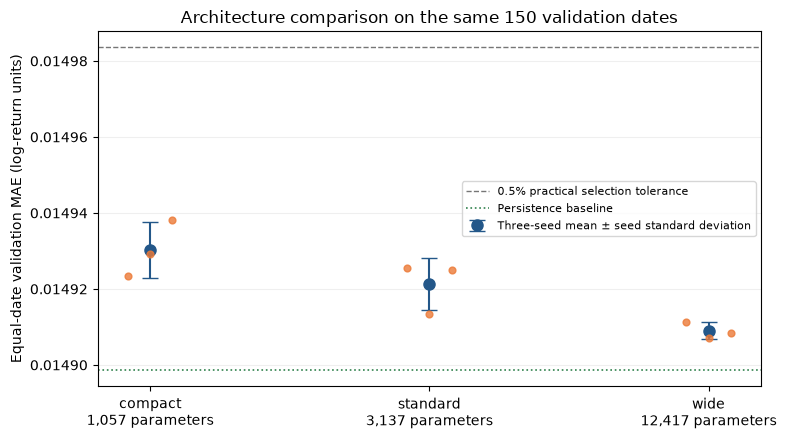

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
positions = np.arange(len(aggregate))
ax.errorbar(positions, aggregate['equal_date_MAE_mean'],
            yerr=aggregate['equal_date_MAE_seed_std'],
            fmt='o', markersize=8, capsize=6, color='#235789',
            label='Three-seed mean ± seed standard deviation')
for position, name in zip(positions, aggregate.index):
    values = runs.loc[runs['model'].eq(name), 'val_day_mae'].to_numpy()
    ax.scatter(np.full(len(values), position) + np.linspace(-0.08, 0.08, len(values)),
               values, color='#ec7a37', alpha=0.8, s=24, zorder=3)
ax.set_xticks(positions, [f'{name}\n{int(aggregate.loc[name, "parameters"]):,} parameters'
                          for name in aggregate.index])
ax.set_ylabel('Equal-date validation MAE (log-return units)')
ax.set_title('Architecture comparison on the same 150 validation dates')
ax.axhline(1.005 * aggregate['equal_date_MAE_mean'].min(), color='#767676',
           linestyle='--', linewidth=1, label='0.5% practical selection tolerance')
ax.axhline(baselines.loc[baselines['model'].eq('persistence'), 'val_day_mae'].iloc[0],
           color='#30814d', linestyle=':', linewidth=1.2, label='Persistence baseline')
ax.grid(axis='y', alpha=0.2)
ax.legend(loc='best', fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / '01_architecture_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

In [4]:
selected_run = runs.loc[
    runs['model'].eq(selected['architecture']) & runs['seed'].eq(42)
].iloc[0]
widths = ' → '.join(map(str, [15, *selected['hidden'], 1]))
selected_mean = aggregate.loc[selected['architecture'], 'equal_date_MAE_mean']
best_mean = aggregate['equal_date_MAE_mean'].min()
display(Markdown(
    f"**Frozen architecture: {selected['architecture']} MLP, {widths}, "
    f"{int(selected['parameters']):,} parameters.** "
    f"Its mean equal-date validation MAE across three seeds is {selected_mean:.7f}; "
    f"the lowest candidate mean is {best_mean:.7f}. "
    'This is the smallest architecture within the predeclared 0.5% tolerance. '
    f"The predeclared seed-42 reference restored its best checkpoint from epoch "
    f"{int(selected_run['best_epoch'])} and has equal-date validation MAE "
    f"{selected_run['val_day_mae']:.7f}. "
    'The three-seed average supports architecture selection; the reference checkpoint '
    'is one trained model, not an ensemble.'
))
print(make_model(selected['architecture']))
print('Reference checkpoint:', selected['checkpoint'])
print('Target scaling:', summary['target_scaler'])
print('Hardware:')
print(json.dumps(summary['hardware'], indent=2))
print('Measured inference benchmark:')
display(inference)

**Frozen architecture: compact MLP, 15 → 32 → 16 → 1, 1,057 parameters.** Its mean equal-date validation MAE across three seeds is 0.0149302; the lowest candidate mean is 0.0149090. This is the smallest architecture within the predeclared 0.5% tolerance. The predeclared seed-42 reference restored its best checkpoint from epoch 1 and has equal-date validation MAE 0.0149292. The three-seed average supports architecture selection; the reference checkpoint is one trained model, not an ensemble.

ReturnMLP(
  (network): Sequential(
    (0): Linear(in_features=15, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)
Reference checkpoint: data/processed/nifty_models/frozen_mlp.pt
Target scaling: {'scale': 0.07981475234487422, 'center': 0.0, 'observed_train_mean': -0.0003261493284968819, 'fit_rows': 7069922, 'fit_split': 'train', 'clipping': False}
Hardware:
{
  "system": "Darwin",
  "machine": "x86_64",
  "logical_cpus": 16,
  "device": "cpu",
  "torch_threads": 4,
  "versions": {
    "torch": "2.2.2",
    "numpy": "1.26.4",
    "pandas": "2.3.3"
  }
}
Measured inference benchmark:


,model,batch_size,repeats,median_batch_ms,p95_batch_ms,rows_per_second
0,compact,1,500,0.0528130,0.0694600,"18,934.7319789"
1,compact,4096,50,0.2064075,0.2457666,"19,844,240.1560021"
2,standard,1,500,0.0506060,0.1022914,"19,760.5027072"
3,standard,4096,50,0.7823650,1.0864679,"5,235,408.0256658"
4,wide,1,500,0.0650335,0.1382707,"15,376.6904749"
5,wide,4096,50,1.8378860,2.5672972,"2,228,647.4786793"


Training times above include optimization, per-epoch validation and training-probe evaluation, best-checkpoint restoration, and checkpoint/prediction saving for each run. They exclude initial data verification, ridge fitting, and the later timing benchmark. The recorded hardware/software configuration makes those measurements interpretable.

Inference is a warm CPU microbenchmark with 20 warm-up calls, then 500 repeats for batch size 1 and 50 repeats for batch size 4,096. It times the model forward pass and target rescaling, excluding I/O, feature construction, and queuing. Median and 95th-percentile times are per batch; throughput is derived from the median batch time. These are local measurements, not production service latency guarantees.

An architecture winning among MLP candidates does not itself establish that it beats persistence or ridge. Read the baseline table alongside the MLP table, and retain all references in the final held-out comparison. Improvements in one metric can coexist with worse tail-sensitive RMSE or price error; the primary metric was specified before comparing results.

**Baseline comparison:** persistence equal-date MAE is 0.0148986; the best ridge (alpha=1) scores 0.0155933; the frozen MLP scores 0.0149292, 0.21% higher than persistence. Persistence remains at least as strong on the primary validation metric; the MLP is fixed as the neural benchmark. This compares one frozen reference checkpoint with the non-neural baselines. Architecture selection uses the three-seed means reported above.

**Metric trade-off:** pooled return RMSE changes from 0.0437919 to 0.0415746 (5.06% reduction), but price MAE changes from 1.70668 to 1.71736 and price RMSE from 4.07129 to 4.11987. The MLP has not demonstrated an overall improvement over persistence.

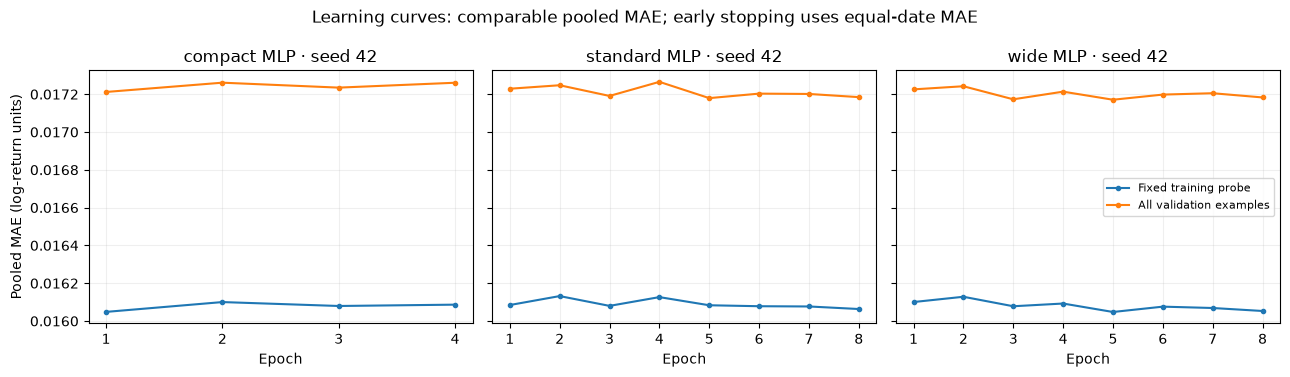

Training probe: fixed 65,536 training examples, sampled with seed 9102.
The probe is diagnostic only; all training rows participate in optimization.


In [5]:
persistence = baselines.loc[baselines['model'].eq('persistence')].iloc[0]
best_ridge = baselines.loc[~baselines['model'].eq('persistence')].sort_values('val_day_mae').iloc[0]
reference_improvement = 100 * (1 - selected_run['val_day_mae'] / persistence['val_day_mae'])
relation = 'lower' if reference_improvement >= 0 else 'higher'
primary_conclusion = (
    'The reference MLP improves the primary metric on validation; final held-out performance is unmeasured.'
    if reference_improvement > 0 else
    'Persistence remains at least as strong on the primary validation metric; the MLP is fixed as the neural benchmark.'
)
rmse_improvement = 100 * (1 - selected_run['val_rmse'] / persistence['val_rmse'])
display(Markdown(
    f"**Baseline comparison:** persistence equal-date MAE is {persistence['val_day_mae']:.7f}; "
    f"the best ridge (alpha={best_ridge['alpha']:g}) scores {best_ridge['val_day_mae']:.7f}; "
    f"the frozen MLP scores {selected_run['val_day_mae']:.7f}, "
    f"{abs(reference_improvement):.2f}% {relation} than persistence. "
    f'{primary_conclusion} '
    'This compares one frozen reference checkpoint with the non-neural baselines. '
    'Architecture selection uses the three-seed means reported above.'
))
display(Markdown(
    f"**Metric trade-off:** pooled return RMSE changes from {persistence['val_rmse']:.7f} "
    f"to {selected_run['val_rmse']:.7f} ({rmse_improvement:.2f}% reduction), but "
    f"price MAE changes from {persistence['val_price_mae']:.5f} to "
    f"{selected_run['val_price_mae']:.5f} and price RMSE from "
    f"{persistence['val_price_rmse']:.5f} to {selected_run['val_price_rmse']:.5f}. "
    'The MLP has not demonstrated an overall improvement over persistence.'
))
learning = history.loc[history['seed'].eq(42)]
from matplotlib.ticker import MaxNLocator
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (name, group) in zip(axes, learning.groupby('model', sort=False)):
    ax.plot(group['epoch'], group['train_probe_mae'], marker='.', label='Fixed training probe')
    ax.plot(group['epoch'], group['val_mae'], marker='.', label='All validation examples')
    ax.set(title=f'{name} MLP · seed 42', xlabel='Epoch')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.2)
axes[0].set_ylabel('Pooled MAE (log-return units)')
axes[-1].legend(fontsize=8)
fig.suptitle('Learning curves: comparable pooled MAE; early stopping uses equal-date MAE')
fig.tight_layout()
fig.savefig(FIGURES / '02_learning_curves.png', dpi=160, bbox_inches='tight')
plt.show()
print('Training probe: fixed 65,536 training examples, sampled with seed 9102.')
print('The probe is diagnostic only; all training rows participate in optimization.')

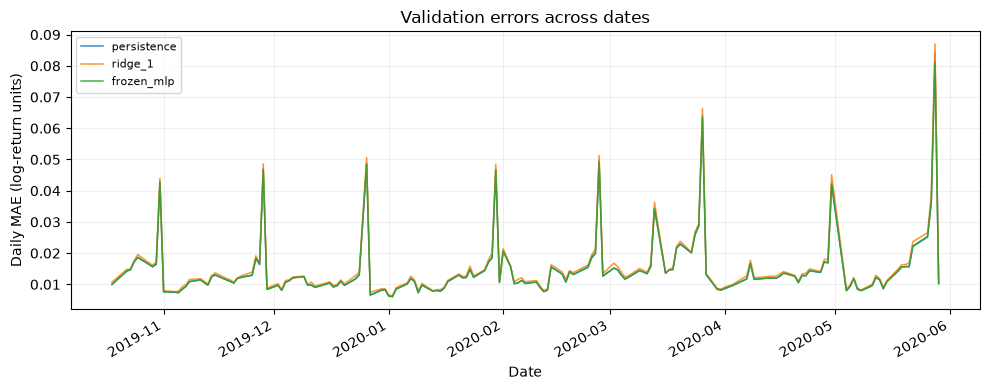

,group,model,rows,val_day_mae,val_rmse,val_price_mae
0,calls,persistence,979825,0.0153609,0.0452365,1.5571525
1,calls,frozen_mlp,979825,0.0153660,0.0428209,1.5598477
2,puts,persistence,1029993,0.0143452,0.0423719,1.8489241
3,puts,frozen_mlp,1029993,0.0144047,0.0403533,1.8671955
4,zero_volume,persistence,2,0.0391550,0.0486645,0.1500000
5,zero_volume,frozen_mlp,2,0.0345540,0.0479646,0.1277071
6,positive_volume,persistence,2009816,0.0148986,0.0437919,1.7066814
7,positive_volume,frozen_mlp,2009816,0.0149292,0.0415746,1.7173591
8,close_at_most_1,persistence,46052,0.0643837,0.2307111,0.0310052
9,close_at_most_1,frozen_mlp,46052,0.0653224,0.2122006,0.0315109


**Where the RMSE change occurs:** for close prices at most 1, return RMSE changes from 0.230711 to 0.212201 (8.0% lower). For prices above 1, it changes from 0.026730 to 0.026702 (0.1% lower). The aggregate return-RMSE benefit is concentrated in the low-price group. The zero-volume validation group contains only **2 examples**; its scores do not support a robust subgroup conclusion.

**Date-block sensitivity:** the mean frozen-MLP-minus-persistence daily MAE difference is 0.0000306; the descriptive 95% block-resampling interval is [-0.0000208, 0.0000699]. Negative favors the MLP. The interval includes zero, so it does not establish a clear MAE advantage. Method: 2000 circular moving-block resamples of validation days; block length 5; seed 8801. Exploratory validation comparison after architecture selection, not an unbiased test confidence interval; nonstationarity may invalidate block assumptions. The listed quality groups overlap and their sample counts should not be added.

In [6]:
daily_wide = daily.pivot(index='day', columns='model', values='mae').sort_index()
daily_wide.index = pd.to_datetime(daily_wide.index)
assert len(daily_wide) == 150
fig, ax = plt.subplots(figsize=(10, 4))
for name in ['persistence', best_ridge['model'], 'frozen_mlp']:
    ax.plot(daily_wide.index, daily_wide[name], label=name, linewidth=1.1, alpha=0.85)
ax.set(title='Validation errors across dates', ylabel='Daily MAE (log-return units)', xlabel='Date')
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIGURES / '03_daily_validation_errors.png', dpi=160, bbox_inches='tight')
plt.show()
subgroups = pd.read_csv(REPORT / 'subgroups.csv')
display(subgroups[['group', 'model', 'rows', 'val_day_mae', 'val_rmse', 'val_price_mae']])
group_metrics = subgroups.set_index(['group', 'model'])
low_price = group_metrics.loc['close_at_most_1']
higher_price = group_metrics.loc['close_above_1']
low_price_gain = 100 * (1 - low_price.loc['frozen_mlp', 'val_rmse'] / low_price.loc['persistence', 'val_rmse'])
higher_price_gain = 100 * (1 - higher_price.loc['frozen_mlp', 'val_rmse'] / higher_price.loc['persistence', 'val_rmse'])
zero_volume_rows = int(group_metrics.loc[('zero_volume', 'frozen_mlp'), 'rows'])
display(Markdown(
    f"**Where the RMSE change occurs:** for close prices at most 1, return RMSE "
    f"changes from {low_price.loc['persistence', 'val_rmse']:.6f} to "
    f"{low_price.loc['frozen_mlp', 'val_rmse']:.6f} ({low_price_gain:.1f}% lower). "
    f"For prices above 1, it changes from {higher_price.loc['persistence', 'val_rmse']:.6f} "
    f"to {higher_price.loc['frozen_mlp', 'val_rmse']:.6f} ({higher_price_gain:.1f}% lower). "
    'The aggregate return-RMSE benefit is concentrated in the low-price group. '
    f"The zero-volume validation group contains only **{zero_volume_rows} examples**; "
    'its scores do not support a robust subgroup conclusion.'
))
uncertainty = summary['uncertainty']
low, high = uncertainty['descriptive_95pct_interval']
interval_conclusion = ('The interval includes zero, so it does not establish a clear MAE advantage. '
                       if low <= 0 <= high else '')
display(Markdown(
    '**Date-block sensitivity:** the mean frozen-MLP-minus-persistence daily MAE '
    f"difference is {uncertainty['mean_difference']:.7f}; the descriptive 95% "
    f"block-resampling interval is [{low:.7f}, {high:.7f}]. Negative favors the MLP. "
    f'{interval_conclusion}'
    f"Method: {uncertainty['method']}. {uncertainty['caveat']}. "
    'The listed quality groups overlap and their sample counts should not be added.'
))

The training probe and validation data come from different chronological periods, so their error gap reflects both fit and changes in the data distribution. It is not a pure measure of overfitting. Daily and subgroup tables help identify uneven performance that a pooled score can hide. The block-resampling interval is exploratory because model development has already used validation outcomes.

The next cell reloads the frozen local checkpoint, verifies its recorded checksum, and predicts a small validation batch. It checks artifact usability without touching the test partition. The training workflow separately verified an exact full-validation prediction match after reloading the frozen checkpoint.

In [7]:
import hashlib
import torch
from nifty_models import predict_batches

checkpoint_path = ROOT / selected['checkpoint']
assert hashlib.sha256(checkpoint_path.read_bytes()).hexdigest() == selected['checkpoint_sha256']
assert hashlib.sha256((DATA / 'manifest.json').read_bytes()).hexdigest() == selected['preprocessing_manifest_sha256']
assert hashlib.sha256((DATA / 'scaler.json').read_bytes()).hexdigest() == summary['protocol']['feature_scaler_sha256']
assert hashlib.sha256((ROOT / 'scripts/nifty_models.py').read_bytes()).hexdigest() == summary['protocol']['model_source_sha256']
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
frozen_model = make_model(checkpoint['architecture'], checkpoint['input_dim'])
frozen_model.load_state_dict(checkpoint['state_dict'])
X_valid = np.load(DATA / 'valid/X.npy', mmap_mode='r')
small_predictions = predict_batches(frozen_model, X_valid[:256], checkpoint['target_scale'])
assert small_predictions.shape == (256,)
assert np.isfinite(small_predictions).all()
assert summary['checkpoint_reload_exact_match']
assert checkpoint['seed'] == 42
assert checkpoint['target_scale'] == summary['target_scaler']['scale']
print('Checkpoint/provenance checksums, model shape, scaling, and finite predictions verified.')
print('First five validation-batch predictions:', small_predictions[:5])
verification = json.loads((REPORT / 'verification.json').read_text())
assert verification['status'] == 'passed'
assert verification['frozen_checkpoint_sha256'] == selected['checkpoint_sha256']
assert verification['mlp_runs_verified'] == 9
assert not verification['test_arrays_or_metadata_opened']
display(Markdown(
    '**Independent full replay passed:** '
    f"{verification['candidate_predictions_exactly_verified']:,} candidate validation predictions "
    f"across all nine runs and {verification['frozen_predictions_exactly_verified']:,} "
    'frozen-checkpoint predictions matched exactly. Baseline scores, metrics, '
    'architecture aggregates, selection, weights, and recorded source/input hashes were also checked. '
    'This verifies implementation consistency; it does not establish out-of-sample predictive skill.'
))

Checkpoint/provenance checksums, model shape, scaling, and finite predictions verified.
First five validation-batch predictions: [ 0.00023355  0.00023355  0.00023355 -0.00073929  0.00657815]


**Independent full replay passed:** 18,088,362 candidate validation predictions across all nine runs and 2,009,818 frozen-checkpoint predictions matched exactly. Baseline scores, metrics, architecture aggregates, selection, weights, and recorded source/input hashes were also checked. This verifies implementation consistency; it does not establish out-of-sample predictive skill.

## 4. Other deep learning techniques considered

| Technique | Fit to this task and expected performance | Compute / inference considerations |
|---|---|---|
| MLP | Strong starting point for a small engineered feature vector; cannot recover within-window order discarded by summaries | Small parameter count, parallel dense operations, inexpensive CPU inference |
| Residual MLP / FT-Transformer | Residual connections or attention across feature tokens can use the existing tabular features; useful future capacity/interaction comparisons | Extra blocks or feature-token attention add compute relative to the compact plain MLP; gains must justify cost |
| GRU / LSTM | Can learn ordered temporal dependencies if a longer, causal bar sequence is built; gains over an MLP are an empirical question | Recurrent steps limit time-axis parallelism; more state and latency than the small MLP |
| Causal 1-D CNN / TCN | Learns local return/volume patterns with a fixed receptive field; worth testing when richer history is available | Parallel convolutions; dilations extend the receptive field efficiently, but causality and padding need checks |
| Time-series Transformer | Potentially useful with much longer contexts and cross-series information; six summarized bars do not justify attention by themselves | Attention and larger embeddings increase memory/compute; inference and data requirements depend on context and model size |

These are hypotheses for later experiments, not performance rankings measured on this dataset. A Transformer is an architecture; it is not automatically an LLM. An LLM is a language-pretrained model and is not needed to fit the present numerical baseline.

Published comparisons support a cautious baseline-first approach. [Gorishniy et al.](https://papers.nips.cc/paper/2021/hash/9d86d83f925f2149e9edb0ac3b49229c-Abstract.html) show that standard tabular-network baselines can be competitive; [Grinsztajn et al.](https://arxiv.org/abs/2207.08815) demonstrate that tree ensembles remain strong on many medium-sized tabular problems. Neither paper establishes which model wins on this option dataset. [Bai et al.](https://arxiv.org/abs/1803.01271) compare temporal convolutions with recurrent models across sequence benchmarks, while [PatchTST](https://arxiv.org/abs/2211.14730) and [DLinear](https://ojs.aaai.org/index.php/AAAI/article/view/26317) highlight different trade-offs in time-series forecasting. Those datasets and forecast horizons differ from one-minute option returns, so their results motivate comparisons rather than guaranteeing an improvement here.

## 5. Future LLM phase — planning only

Following the repository's model-validation scope, the proposed LLM role is **structured test and stress-scenario proposal**, with a deterministic local evaluator judging every proposal. No LLM calls, model downloads, or LLM-directed experiments are performed in this notebook.

1. **Freeze the numerical benchmark.** Save the selected MLP, persistence/ridge references, feature ordering, target/feature scalers, provenance, and evaluation code. Establish which development data can be used and a fixed experiment budget. Predeclare useful-failure definitions and thresholds using training diagnostics or explicit numerical/input contracts before asking any proposal generator; do not let each generator redefine success. Keep final test labels/results outside prompts and model selection.
2. **Give the LLM a constrained specification.** Provide the task, input definitions, verified data limits, and aggregated training/validation diagnostics. Ask for structured JSON containing a hypothesis, proposed stress case or diagnostic, required fields, constraints, expected failure mode, and a measurable acceptance criterion. Do not ask it to invent expiry, underlying prices, quotes, or observed results.
3. **Validate proposals before execution.** Check JSON schema, allowlisted diagnostic types, data availability, causal timing, physical/numerical bounds, duplicate tests, and resource limits. Human review can assess semantic plausibility; deterministic Python implements approved tests. LLM text is a proposal, not an executable script or a ground-truth label.
4. **Use valid diagnostic families.** Evaluate existing low-price, zero-volume, flat-bar, call/put, time-of-day, and date/regime groups; examine large-return tails and missing-history handling. Synthetic raw-bar scenarios must preserve positive prices, coherent OHLC, nonnegative volume, consecutive timestamps, and consistent feature recomputation. Input perturbations with an unchanged observed label measure sensitivity to measurement noise only. Initially restrict such corruption to volume or non-anchor OHLC values. If current close changes, retain the observed future close and recompute the return target consistently with the new anchor; otherwise target/predicted-price comparisons are invalid. A counterfactual market path needs an explicit simulator and target definition; the LLM cannot invent an observed ground-truth target. Synthetic stress cases test robustness, not empirical forecast accuracy.
5. **Measure the LLM's contribution.** Start with 100 proposed cases per method per seed, using three predeclared seeds: LLM, predefined human-written/fixed-rule, and random scenarios, each with the same per-case evaluation/resource limits. Prioritize queries on observed validation rows with real targets before synthetic scenarios. Track schema validity, runnable proposals, unique reproducible failures or failure episodes, false alarms, useful coverage, latency, and cost. Compare failure discovery per proposal, with a matched-valid-case comparison as a secondary diagnostic. Re-run useful findings deterministically and log model/version, prompts, seeds, and accepted/rejected cases.
6. **Close development before final evaluation.** If tests lead to model changes, use training/validation only and document the additional tuning. Freeze the entire pipeline again before one final test comparison. Results on validation after repeated LLM-guided exploration remain development results.

The LLM's role is limited to assisting error analysis and stress-test design. The numerical baseline remains the forecasting model.

## 6. Copy-ready check-in answers

The following answers include the actual architecture decision and measured validation results. The comparison with persistence/ridge remains visible above; no test-set or LLM result is claimed.

In [8]:
reference_latency = inference.loc[
    inference['model'].eq(selected['architecture']) & inference['batch_size'].eq(1),
    'median_batch_ms'
].iloc[0]
answer = f"""
**1. What architectures did we consider based on EDA?** We predict next-minute option log returns from 15 features summarizing six consecutive bars. Because the inputs are tabular, we tested three standard ReLU MLPs: **15–32–16–1**, **15–64–32–1**, and **15–128–64–32–1**, containing **1,057**, **3,137**, and **12,417** parameters. Each has 10% dropout and a linear output for signed returns. Small networks suit the existing representation and limit unnecessary capacity despite millions of correlated examples.

**2. What baseline did we build and fix?** We compared the MLPs with **zero-return/persistence** and **ridge regression**. All MLPs used **7,069,922 training examples**, **2,009,818 validation examples**, and three seeds. Training used AdamW, weight decay, Smooth L1 loss, training-only target scaling, and early stopping. We fixed the **{selected['architecture']} MLP ({widths}; {int(selected['parameters']):,} parameters)** using the smallest-model-within-0.5%-of-best rule. Its three-seed mean equal-date validation MAE is **{selected_mean:.7f}**. The seed-42 checkpoint scores **{selected_run['val_day_mae']:.7f}**, versus **{persistence['val_day_mae']:.7f}** for persistence and **{best_ridge['val_day_mae']:.7f}** for the best ridge. {primary_conclusion} Its return RMSE is **{rmse_improvement:.1f}% lower** than persistence, mainly from low-price options, but price errors worsen. Ridge and MLP use different losses, so the comparison is not solely an architecture effect. The **2,389,879 test examples remain unused** for fitting and model selection.

**3. How do the deep learning alternatives compare?** MLPs directly fit the current feature vectors: the frozen run took **{selected_run['train_seconds'] / 60:.1f} minutes** including validation/checkpoint work, and warm CPU inference had median **{reference_latency:.3f} ms per example** at batch size 1, excluding data preparation. **LSTM/GRU** could learn ordered dependencies from a rebuilt sequence dataset but add recurrent computation. **Causal CNN/TCN** can learn local patterns with parallel convolutions. **Time-series Transformers** can model longer context but add compute and need an appropriate sequence dataset; **FT-Transformer** could instead attend across the existing tabular features. [Tabular](https://arxiv.org/abs/2106.11959) and [sequence-model](https://arxiv.org/abs/1803.01271) research motivates these alternatives; their performance on this dataset remains untested.

**4. What is the later LLM plan?** Use an LLM to propose structured error-analysis and stress tests for the fixed numerical model, starting with observed validation records and real targets. Validate proposals against a JSON schema and data/causality constraints, then evaluate them with deterministic Python. Compare useful failures, coverage, false alarms, latency, and cost against equal-budget fixed-rule and random test suites. Keep test data outside this development loop. **The LLM phase is planned only and has not started.**
"""
display(Markdown(answer))


**1. What architectures did we consider based on EDA?** We predict next-minute option log returns from 15 features summarizing six consecutive bars. Because the inputs are tabular, we tested three standard ReLU MLPs: **15–32–16–1**, **15–64–32–1**, and **15–128–64–32–1**, containing **1,057**, **3,137**, and **12,417** parameters. Each has 10% dropout and a linear output for signed returns. Small networks suit the existing representation and limit unnecessary capacity despite millions of correlated examples.

**2. What baseline did we build and fix?** We compared the MLPs with **zero-return/persistence** and **ridge regression**. All MLPs used **7,069,922 training examples**, **2,009,818 validation examples**, and three seeds. Training used AdamW, weight decay, Smooth L1 loss, training-only target scaling, and early stopping. We fixed the **compact MLP (15 → 32 → 16 → 1; 1,057 parameters)** using the smallest-model-within-0.5%-of-best rule. Its three-seed mean equal-date validation MAE is **0.0149302**. The seed-42 checkpoint scores **0.0149292**, versus **0.0148986** for persistence and **0.0155933** for the best ridge. Persistence remains at least as strong on the primary validation metric; the MLP is fixed as the neural benchmark. Its return RMSE is **5.1% lower** than persistence, mainly from low-price options, but price errors worsen. Ridge and MLP use different losses, so the comparison is not solely an architecture effect. The **2,389,879 test examples remain unused** for fitting and model selection.

**3. How do the deep learning alternatives compare?** MLPs directly fit the current feature vectors: the frozen run took **0.5 minutes** including validation/checkpoint work, and warm CPU inference had median **0.053 ms per example** at batch size 1, excluding data preparation. **LSTM/GRU** could learn ordered dependencies from a rebuilt sequence dataset but add recurrent computation. **Causal CNN/TCN** can learn local patterns with parallel convolutions. **Time-series Transformers** can model longer context but add compute and need an appropriate sequence dataset; **FT-Transformer** could instead attend across the existing tabular features. [Tabular](https://arxiv.org/abs/2106.11959) and [sequence-model](https://arxiv.org/abs/1803.01271) research motivates these alternatives; their performance on this dataset remains untested.

**4. What is the later LLM plan?** Use an LLM to propose structured error-analysis and stress tests for the fixed numerical model, starting with observed validation records and real targets. Validate proposals against a JSON schema and data/causality constraints, then evaluate them with deterministic Python. Compare useful failures, coverage, false alarms, latency, and cost against equal-budget fixed-rule and random test suites. Keep test data outside this development loop. **The LLM phase is planned only and has not started.**


## 7. Reproducibility and references

The experiment artifacts under `reports/nifty_models/` record configuration, actual validation measurements, training histories, timing, and the architecture decision. Local model checkpoints are excluded from version control. For a fresh experiment, run `python scripts/train_nifty_models.py` followed by `python scripts/verify_nifty_models.py`; completed experiments are guarded against accidental overwrites. Regenerate this notebook with `python scripts/build_nifty_models_notebook.py`, execute it with the repository `.conda` kernel, and export it to `reports/nifty_models/models.html`. Notebook execution reads existing verified results, saves the three standalone PNGs under `reports/nifty_models/figures/`, and performs the small checkpoint-usability check. It does not repeat training or open test arrays.

Primary references:

- [Gorishniy et al., Revisiting Deep Learning Models for Tabular Data (2021)](https://arxiv.org/abs/2106.11959): standard tabular neural baselines and FT-Transformer.
- [Grinsztajn et al., Why do tree-based models still outperform deep learning on typical tabular data? (2022)](https://arxiv.org/abs/2207.08815): evidence for retaining strong non-neural comparisons.
- [Bai et al., An Empirical Evaluation of Generic Convolutional and Recurrent Networks for Sequence Modeling (2018)](https://arxiv.org/abs/1803.01271): empirical TCN/recurrent comparisons.
- [Nie et al., A Time Series is Worth 64 Words: Long-term Forecasting with Transformers (2023)](https://arxiv.org/abs/2211.14730): PatchTST, a purpose-built time-series Transformer.
- [Zeng et al., Are Transformers Effective for Time Series Forecasting? (2023)](https://arxiv.org/abs/2205.13504): linear time-series baselines and benchmarking caveats.
- [PyTorch SmoothL1Loss](https://pytorch.org/docs/stable/generated/torch.nn.SmoothL1Loss.html), [AdamW](https://pytorch.org/docs/stable/generated/torch.optim.AdamW.html), and [Dropout](https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html): implementation definitions.
- [scikit-learn: data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage): fitting preprocessing only with training data.

Research motivates architecture choices; the saved local experiments supply all dataset-specific performance claims. No result here demonstrates future profitability or substitutes for a final held-out evaluation.